# Problem

## Separate elastic scattering from intrinsic seismic absorption

The benchmark contains actual three-component broadband measurements of five German earthquakes at five regional stations. We infer frequency-dependent scattering and absorption together with source spectra and relative site amplifications. These quantities explain different parts of a common decaying waveform envelope and are coupled. There is no independent ground truth for these effective crustal parameters. Crosses and method-reference metrics below identify our independent original Qopen execution, not measured truth and not historical paper results.

The selected experiment comprises **all 24 acquired records and all 25 event-frequency fits**. It is a regional effective transport inversion, not a resolved three-dimensional tomographic image. The motivating paper compares intrinsic/scattering attenuation and station effects; this notebook preserves those scientific comparisons for the actual author-distributed example acquisition, without claiming to reproduce the larger paper survey.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,prepare_band
from src.solvers import reconstruct
from src.visualization import (log_ratio_metrics,acquisition_figure,spectra_figure,diagnostics_figure,fixed_scattering_comparison,ablation_figure)
spec=importlib.util.spec_from_file_location('task_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
data=load_data(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as z: original={k:z[k] for k in z.files}
review=Path(os.environ.get('IMAGING_REVIEW_DIR',str(ROOT.parent.parent/'archive/review')));review.mkdir(parents=True,exist_ok=True)
def display_figure(fig,name):
    fig.savefig(review/('qopen_'+name+'.png'),dpi=130)
    plt.show()
print('Measured records:',data['valid'].sum(),'accepted record/band pairs:',data['fit_valid'].sum())
print('No cached reconstruction path: all fits below execute cleaned modules.')

Measured records: 24 accepted record/band pairs: 119
No cached reconstruction path: all fits below execute cleaned modules.


# Data

The GR network records were downloaded by the original authors from the BGR EIDA service; station response information comes from the accompanying inventory and earthquake origins from the accompanying catalogue. The public arrays are the actual native sensitivity-corrected velocities before filtering. Instrument sensitivity is independent of the inferred medium. Sampling is 20 Hz, 4401 samples from -10 to 210 seconds relative to origin, in m/s. Five bands span 0.25–8 Hz. One event lacks one station; a separate observed-coda quality rule excludes one low-frequency station/event pair. Both facts are represented explicitly by masks, not by fabricated measurements.

The author example decimates the original recorded series without a new anti-alias filter. This is an acquisition-processing limitation inherited from the supplied measured data, not a synthetic replacement. Calibrated waveforms and catalogue coordinates remain float64; timestamp-derived onsets retain microsecond precision. The model uses density 2700 kg/m³, S speed 3400 m/s and free-surface energy factor 4. These are fixed model assumptions, not fitted targets.

In [2]:
print('Array shapes:',{k:v.shape for k,v in data.items()})
print('Band edges [Hz]:',data['frequency_bands'])
print('Station identity per event slot:',data['station_index'])
print('Usable station counts by event/frequency:',data['fit_valid'].sum(axis=-1))

Array shapes: {'velocity': (5, 5, 3, 4401), 'distance': (5, 5), 'start_time': (5, 5), 's_onset': (5, 5), 'frequency_bands': (5, 2), 'valid': (5, 5), 'station_index': (5, 5), 'fit_valid': (5, 5, 5)}
Band edges [Hz]: [[0.25 0.5 ]
 [0.5  1.  ]
 [1.   2.  ]
 [2.   4.  ]
 [4.   8.  ]]
Station identity per event slot: [[ 0  1  2  3  4]
 [ 0  1  2  3  4]
 [ 3  1  4  0  2]
 [ 3  4  1  0  2]
 [ 3  4  0  2 -1]]
Usable station counts by event/frequency: [[5 5 5 5 5]
 [5 5 5 5 5]
 [5 5 5 5 5]
 [4 5 5 5 5]
 [4 4 4 4 4]]


# Physics

For event e, station s and frequency f, the spectral energy density is

$$
E_{es}(t,f)=W_e(f)R_{es}(f)G(r_{es},t;g_e(f))\exp[-b_e(f)t].
$$

Here r is distance in metres, t is seconds since origin, W is source energy in J/Hz, R is dimensionless relative site amplification, g is scattering in inverse metres and b is absorption in inverse seconds. G is a causal transport density in inverse cubic metres. The direct pulse has temporal integral exp(-gr)/(4 pi c r²), with c=3400 m/s. For ct>r, set u=cgt, v=gr and a=1-v²/u²; the scattered component is

$$
G_c=\frac{g^3a^{1/8}}{(4\pi u/3)^{3/2}}\exp[u(a^{3/4}-1)]\sqrt{1+2.026/(ua^{3/4})}.
$$

It vanishes before the wavefront. The bulk average uses a 1000-point direct-plus-coda grid; the coda uses the same Bartlett smoothing as observations. The specified reference discretization omits the first post-wavefront coda bin while retaining the direct pulse, which we preserve and test. This homogeneous, isotropic, infinite-medium approximation does not describe every regional heterogeneity.

For filtered velocity components v and their Hilbert transforms h, spectral energy is the sum of rho(v²+h²)/(2 Δf × 4), where rho is density and Δf is the effective two-pass filter bandwidth. A measured pre-event noise floor is subtracted. Bulk data span S-2 to S+20 seconds; coda begins at S+20 and ends at S+150 or the observed three-noise crossing. Coda samples are temporally correlated.

# Method

The explicit local implementation profiles scattering. For each trial g, let y=log(E)-log(G), let A have one station indicator per usable station and a final column -t, and let x contain station log amplitudes and b. Solve

$$
\min_x \|\sqrt{D}(Ax-y)\|_2^2,\qquad
\log W=\frac{1}{S}\sum_{s=1}^S x_s,\qquad R_s=\exp(x_s)/W.
$$

D is diagonal: coda weights equal one and bulk weights equal their original sample counts. S is the number of valid stations. This fixes the geometric mean site response to one. The optimizer profiles the residual standard error with denominator N-S-1, where N counts coda plus bulk observations. SVD uses the original pseudoinverse cutoff; scalar golden search uses g in [1e-8,1e-4] m^-1 and positive absorption constrained to (0.001,10) s^-1, relative search tolerance 0.001. All 25 solutions are interior.

The method is implemented locally with numerical primitives. Qopen/ObsPy/statsmodels are used only in the private upstream verification environment. The active path below reads the complete public acquisition and reconstructs every required output. No archived reconstruction supplies fresh values.

In [3]:
started=time.perf_counter()
fresh,details=reconstruct(data)
runtime=time.perf_counter()-started
(ROOT/'output').mkdir(exist_ok=True)
np.savez(ROOT/'output/reconstruction.npz',**fresh)
np.savez(ROOT/'notebooks/reference_outputs/cleaned.npz',**fresh)
report,status=judge.evaluate(ROOT/'output/reconstruction.npz')
assert status==0,report
print('Fresh complete reconstruction runtime [s]:',runtime)
print(json.dumps(report,indent=2))
print('Explicit metric cross-check:',log_ratio_metrics(fresh,original,data['fit_valid']))

Fresh complete reconstruction runtime [s]: 1.22097769996617
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_max_abs_log_ratio": 2.997602166487927e-15,
    "source_energy_max_abs_log_ratio": 3.5527136788004946e-15,
    "site_amplification_max_abs_log_ratio": 3.774758283725539e-15,
    "forward_error_boundary_ratio": 0.9514970089364438
  },
  "thresholds": {
    "reconstruction_max_abs_log_ratio": {
      "comparison": "<=",
      "boundary": 0.005
    },
    "source_energy_max_abs_log_ratio": {
      "comparison": "<=",
      "boundary": 0.005
    },
    "site_amplification_max_abs_log_ratio": {
      "comparison": "<=",
      "boundary": 0.005
    },
    "forward_error_boundary_ratio": {
      "comparison": "<=",
      "boundary": 1.0
    }
  },
  "errors": []
}
Explicit metric cross-check: {'reconstruction': 2.997602166487927e-15, 'source_energy': 3.5527136788004946e-15, 'site_amplification': 3.774758283725539e-15}


# Results

The following panels first connect actual velocity measurements to spectral energy, observed windows and fitted coda. Square markers identify measured bulk means. The availability panel accounts for all 25 fits, including the single signal-to-noise exclusion. This provides acquisition and observation-fit context before interpreting recovered parameters.

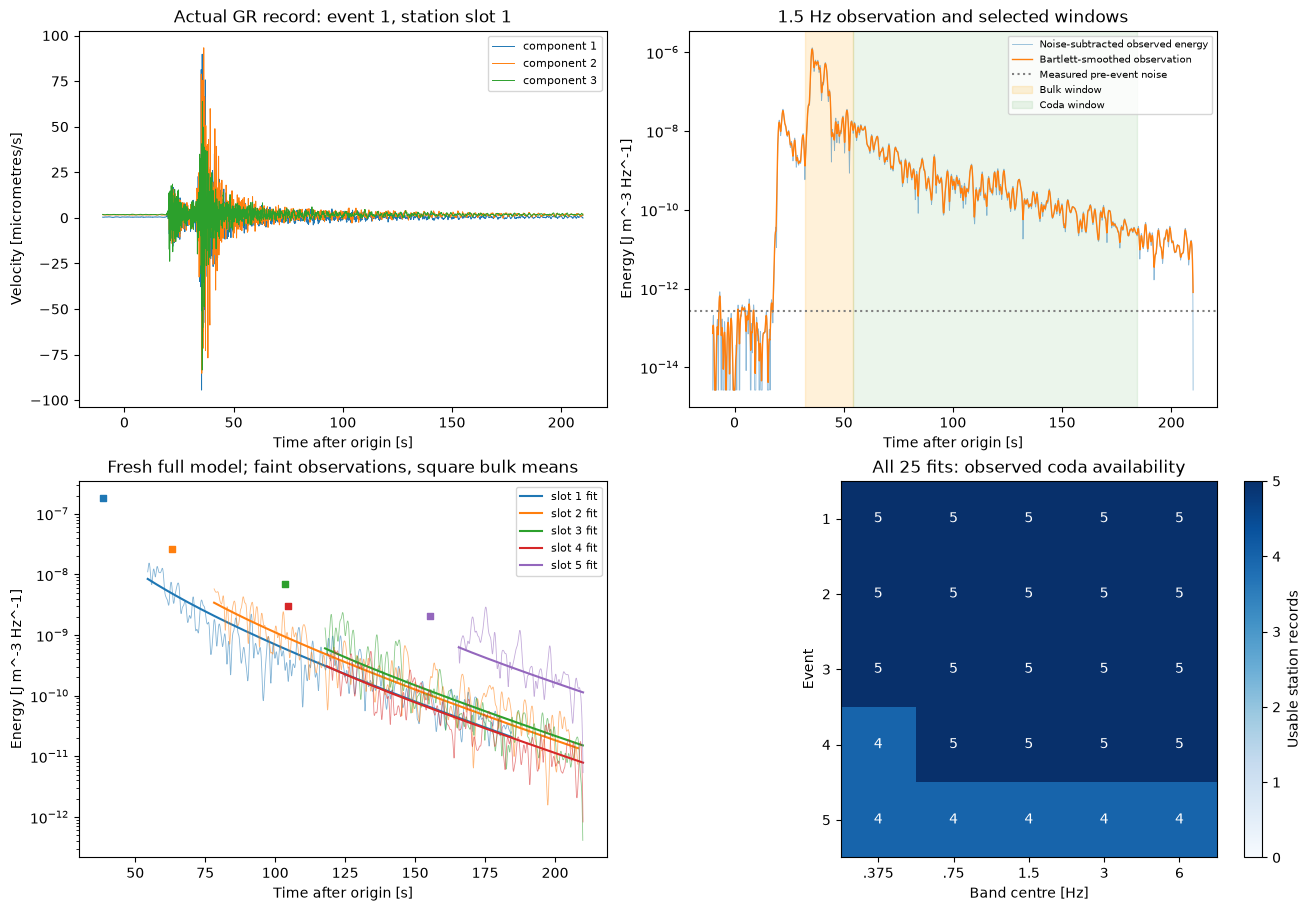

In [4]:
display_figure(acquisition_figure(data,details),'acquisition')

## Scattering, absorption, source and site spectra

Lines below are fresh cleaned-code measurements. Crosses are our independently executed original-method results on the identical acquisition, not historical reported paper numbers. The source scale is conditional on geometric-mean site normalization. Recovered site spectra are grouped by actual station identity, not by event-specific storage slot. Event-to-event variability should not be mistaken for a calibrated confidence interval.

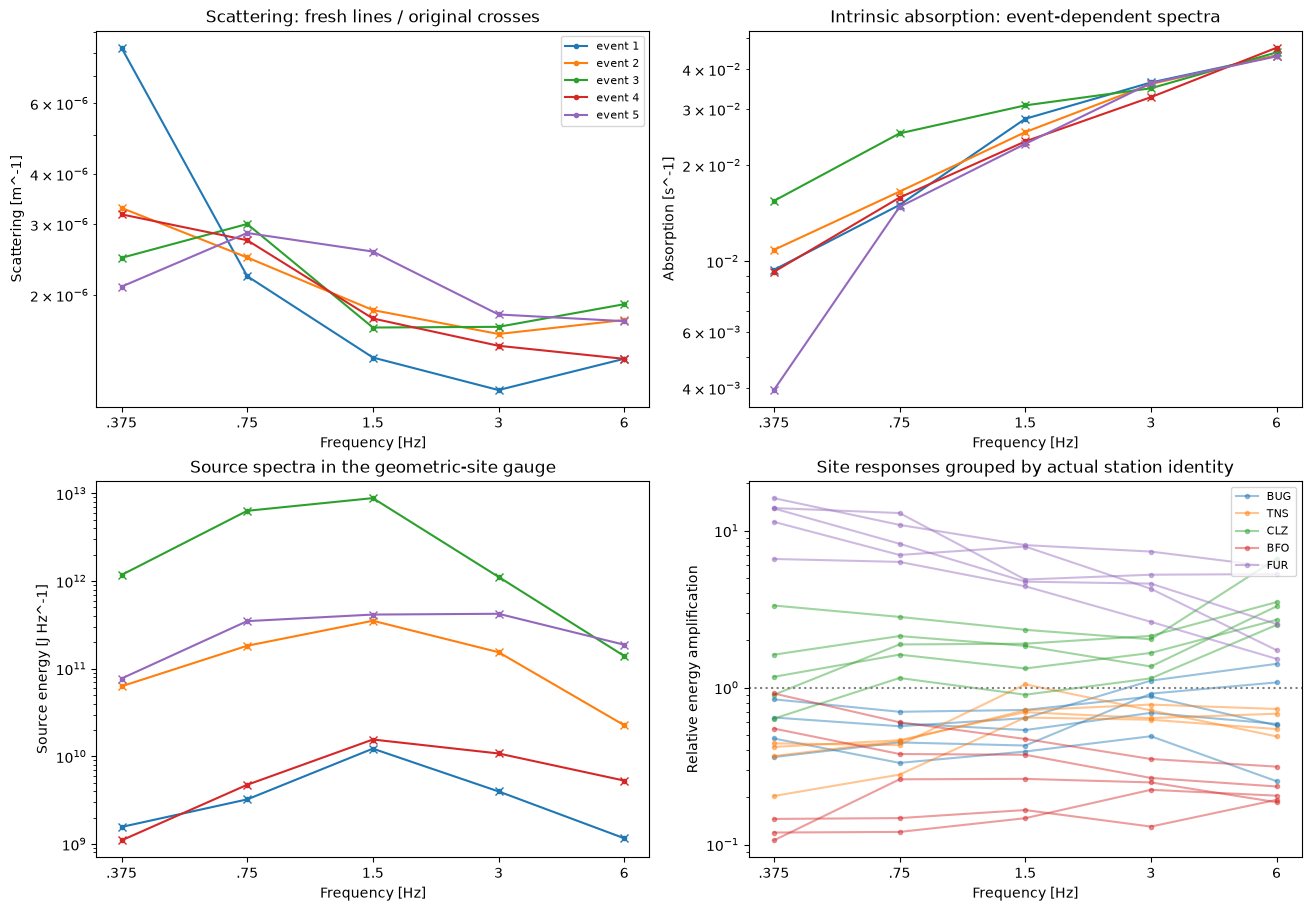

In [5]:
display_figure(spectra_figure(data,fresh,original),'spectra')

## Agreement and residuals

Agreement with the original algorithm is a numerical reproduction check. It cannot establish accuracy to an unavailable physical truth. The nonzero forward residuals reveal that the measured envelopes do not exactly obey the homogeneous transport model. The profile panel re-solves amplitudes and absorption at 81 trial scattering values for a selected actual event/band, exposing coupling. The empirical residual histogram aggregates correlated coda samples and bulk means and is not a chi-square noise calibration.

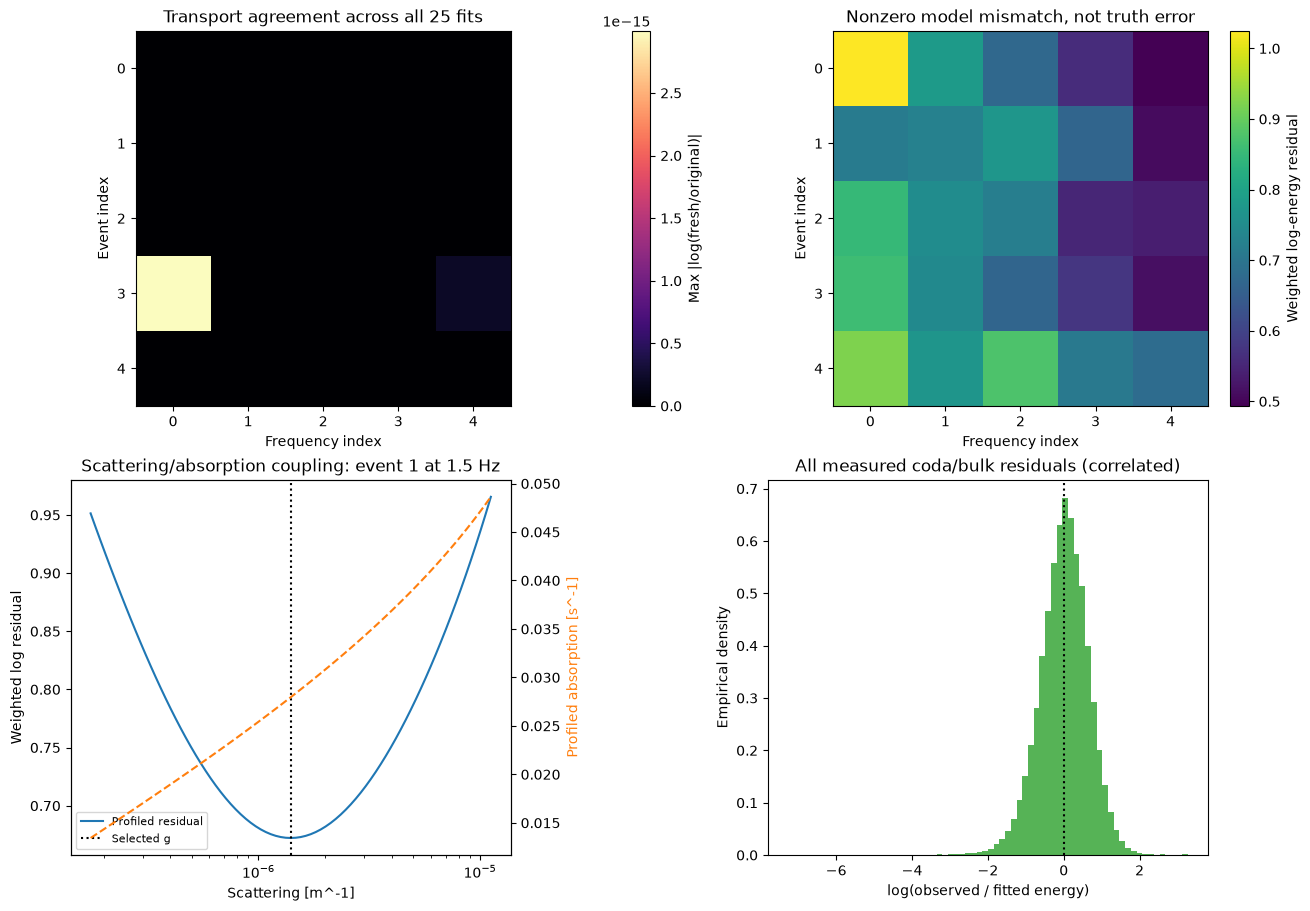

In [6]:
display_figure(diagnostics_figure(data,fresh,original,details),'diagnostics')

## Fresh fixed-scattering comparison

To test the role of scattering variation, choose one common scattering coefficient equal to the geometric mean of the 25 freshly fitted values, then **actually refit** source, sites and absorption separately for each event-frequency pair. This is a conditional ablation using the measured observations, not another published method and not a benchmark output. It does not test independent prediction because the common coefficient was selected from the full fits. The comparison shows residual, absorption and source sensitivity when scattering variation is removed. Any negative profiled absorption in this unconstrained comparison is explicitly counted below.

Common scattering [m^-1]: 2.090032737357942e-06
Nonpositive ablation absorption count: 1
Method | mean weighted log residual | runtime/context
Historical paper survey | not copied | different experiment
Independent original on bound measurements | 0.7063343898608129 | reproduced separately
Fresh complete local transport | 0.7063343898608132 | 1.22097769996617 seconds
Fresh common-scattering ablation | 0.7176366542765585 | all 25 linear profiles recomputed


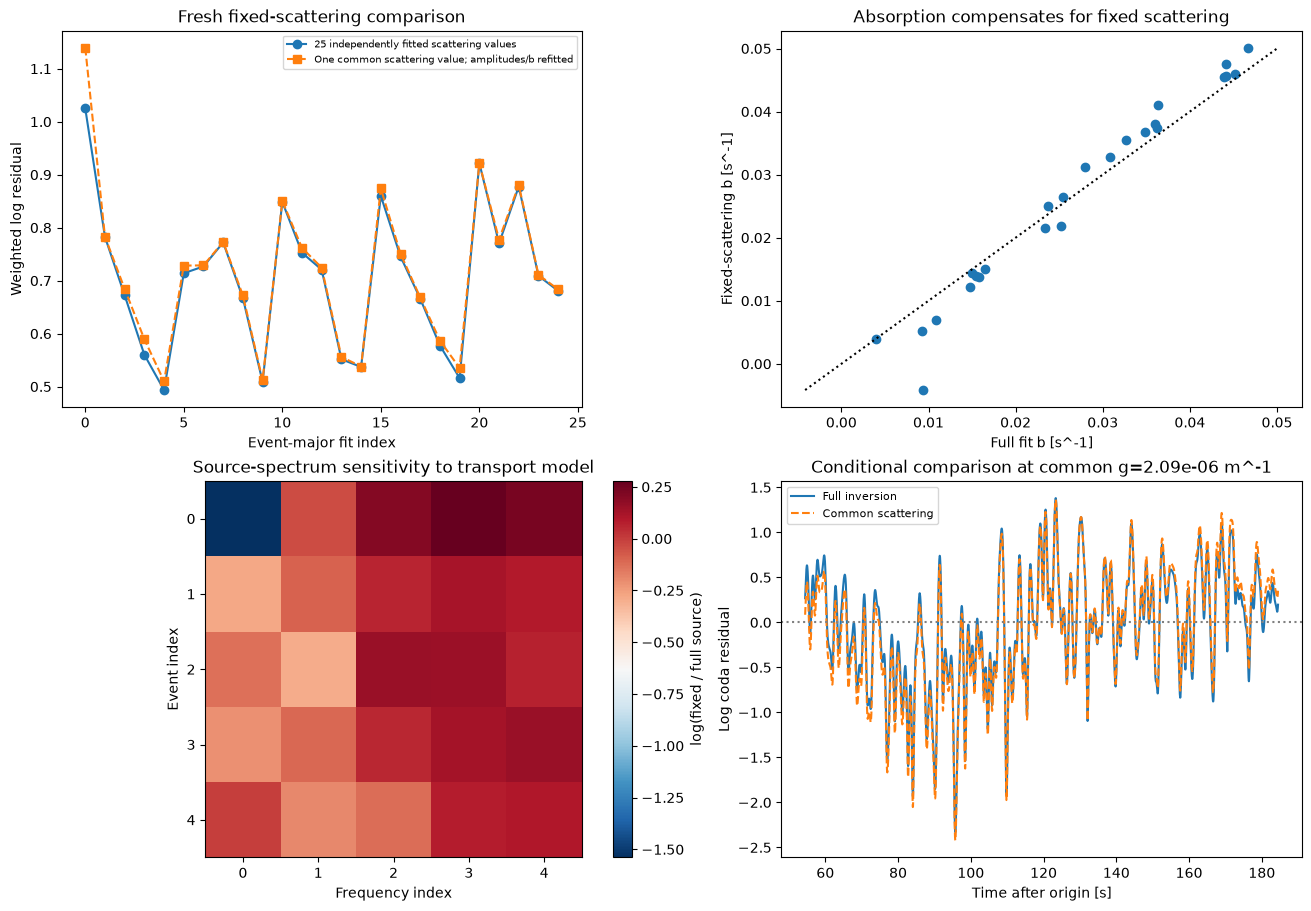

In [7]:
common,fixed=fixed_scattering_comparison(details)
full_error=np.array([[r['error'] for r in row] for row in details])
fixed_error=np.array([[r['error'] for r in row] for row in fixed])
print('Common scattering [m^-1]:',common)
print('Nonpositive ablation absorption count:',sum(r['absorption']<=0 for row in fixed for r in row))
print('Method | mean weighted log residual | runtime/context')
print('Historical paper survey | not copied | different experiment')
print('Independent original on bound measurements |',original['weighted_log_error'].mean(),'| reproduced separately')
print('Fresh complete local transport |',full_error.mean(),'|',runtime,'seconds')
print('Fresh common-scattering ablation |',fixed_error.mean(),'| all 25 linear profiles recomputed')
display_figure(ablation_figure(details,common,fixed),'ablation')

# Conclusion

The fresh complete inversion recovers scattering/absorption spectra and source/site amplitudes consistent with the independent original execution on all bound records. The observations retain nonzero transport-model mismatch; agreement with a standard method is not independent crustal truth. The common-scattering experiment tests the scientific role of spatial/event/frequency variability while exposing compensating source and absorption changes.

Interpretation remains conditional on homogeneous transport, fixed speed/density, noise-window selection, the supplied decimation and the source/site gauge. The profile curve is a sensitivity diagnostic rather than a formal confidence interval. Larger regional maps, Brune source-moment fitting and the paper's full station survey are outside this explicitly selected acquisition; their results are not implied by these plots. The task uses no generated observations, and every displayed fresh result was computed in this notebook.

Method sources: Eulenfeld & Wegler 2016, DOI 10.1093/gji/ggw035; Sens-Schönfelder & Wegler 2006, DOI 10.1111/j.1365-246X.2006.03139.x; Paasschens 1997, DOI 10.1103/PhysRevE.56.1135. Exact source revision, acquisition hashes, independent-run evidence and stage mapping are in `test/validation.md`.